# Regresión  -  Predicción de la nota media del 2º semestre

**Objetivo.** Predecir `nota_media_2sem` (continua) a partir de variables disponibles al inicio y durante el 1er semestre del curso. Es una tarea distinta a la clasificación (`objetivo`) pero sobre el mismo dataset de estudiantes.

**Plan de trabajo (paralelo al de clasificación, adaptado a regresión).**

1. Carga y preparación del dataset + control de data leakage (nada de variables del 2º semestre como predictores).
2. Split train/test 80/20.
3. Pipelines duales: *ordinal* (para modelos basados en árboles) y *one-hot + escalado* (para modelos lineales y basados en distancia).
4. Baseline con `DummyRegressor` (estrategia: la media).
5. Comparación amplia de modelos con CV-5 (lineales regularizados, KNN, árbol, RF, GB, SVR, MLP).
6. Ajuste fino de hiperparámetros con `GridSearchCV` sobre los dos candidatos más prometedores (RF y GB).
7. Selección del modelo final **por CV en train**, no por el test.
8. Evaluación final en test (RMSE, MAE, R^2) + análisis de residuos + curvas de aprendizaje.
9. Interpretabilidad: importancias Gini, permutation importance y SHAP (TreeExplainer).
10. Análisis de errores (casos peor predichos) y conclusiones con triangulación frente a EDA y clasificación.

**Nota sobre data leakage.** Como la variable objetivo es del 2º semestre, se excluyen explícitamente todas las variables `asignaturas_2sem_*` **y** la variable `objetivo` (que depende del desenlace del curso). Solo se usan predictores disponibles hasta el final del 1er semestre.


## 1. Carga y preparación

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

SEED = 42
np.random.seed(SEED)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100

Path("figuras").mkdir(exist_ok=True)

df = pd.read_csv("rendimiento_estudiantes.csv", sep=";")
print(df.shape)
df.head()

(4424, 37)


,estado_civil,modo_solicitud,orden_solicitud,curso,asistencia_diurna_vespertina,cualificacion_previa,nota_cualificacion_previa,nacionalidad,cualificacion_madre,cualificacion_padre,...,asignaturas_2sem_convalidadas,asignaturas_2sem_matriculadas,asignaturas_2sem_evaluadas,asignaturas_2sem_aprobadas,nota_media_2sem,asignaturas_2sem_sin_evaluacion,tasa_desempleo,tasa_inflacion,pib,objetivo
0,soltero/a,2a_fase_contingente_general,5,animacion_y_diseno_multimedia,diurna,educacion_secundaria,122.0,portuguesa,educacion_basica_3er_ciclo_o_equivalente,otro_11o_ano,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,abandono
1,soltero/a,estudiante_internacional_licenciatura,1,turismo,diurna,educacion_secundaria,160.0,portuguesa,educacion_secundaria_12o_ano_o_equivalente,educacion_superior_grado,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,graduado
2,soltero/a,1a_fase_contingente_general,5,diseno_de_comunicacion,diurna,educacion_secundaria,122.0,portuguesa,educacion_basica_1er_ciclo_o_equivalente,educacion_basica_1er_ciclo_o_equivalente,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,abandono
3,soltero/a,2a_fase_contingente_general,2,periodismo_y_comunicacion,diurna,educacion_secundaria,122.0,portuguesa,educacion_basica_2o_ciclo_o_equivalente,educacion_basica_1er_ciclo_o_equivalente,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,graduado
4,casado/a,mayor_de_23_anos,1,servicio_social_nocturno,vespertina,educacion_secundaria,100.0,portuguesa,educacion_basica_1er_ciclo_o_equivalente,educacion_basica_2o_ciclo_o_equivalente,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,graduado


count    4424.000000
mean       10.230206
std         5.210808
min         0.000000
25%        10.750000
50%        12.200000
75%        13.333333
max        18.571429
Name: nota_media_2sem, dtype: float64


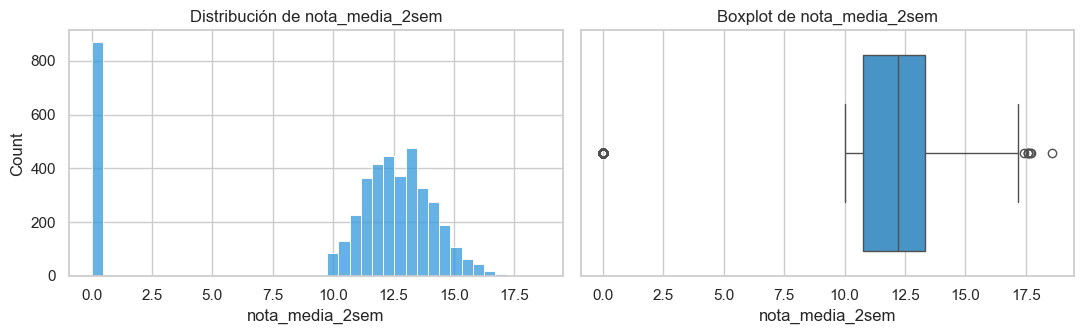

In [2]:
target = "nota_media_2sem"
print(df[target].describe())

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
sns.histplot(df[target], bins=40, ax=ax[0], color="#3498db")
ax[0].set_title("Distribución de nota_media_2sem")
sns.boxplot(x=df[target], ax=ax[1], color="#3498db")
ax[1].set_title("Boxplot de nota_media_2sem")
plt.tight_layout(); plt.show()

En el EDA ya vi que `nota_media_2sem` tiene una masa concentrada en 0 (estudiantes que no se examinaron o abandonaron) y luego una distribución razonablemente continua entre ~10 y ~18. Eso la hace una target un poco "bimodal de facto", y conviene tenerlo presente al leer los errores: el modelo puede acertar muy bien el grupo de 0s y tener más ruido en el rango continuo, o al revés.

## 2. Control de data leakage y separación X / y

In [3]:
leak_cols = [
    "nota_media_2sem",
    "asignaturas_2sem_convalidadas",
    "asignaturas_2sem_matriculadas",
    "asignaturas_2sem_evaluadas",
    "asignaturas_2sem_aprobadas",
    "asignaturas_2sem_sin_evaluacion",
    "objetivo",
]

X = df.drop(columns=leak_cols)
y = df[target].copy()

print("Nº de predictores:", X.shape[1])
print("Predictores:", list(X.columns))

Nº de predictores: 30
Predictores: ['estado_civil', 'modo_solicitud', 'orden_solicitud', 'curso', 'asistencia_diurna_vespertina', 'cualificacion_previa', 'nota_cualificacion_previa', 'nacionalidad', 'cualificacion_madre', 'cualificacion_padre', 'ocupacion_madre', 'ocupacion_padre', 'nota_admision', 'desplazado', 'necesidades_educativas_especiales', 'deudor', 'matricula_al_dia', 'genero', 'becado', 'edad_al_matricularse', 'internacional', 'asignaturas_1sem_convalidadas', 'asignaturas_1sem_matriculadas', 'asignaturas_1sem_evaluadas', 'asignaturas_1sem_aprobadas', 'nota_media_1sem', 'asignaturas_1sem_sin_evaluacion', 'tasa_desempleo', 'tasa_inflacion', 'pib']


Dejo fuera tanto el target como **todo lo del 2º semestre** y la variable `objetivo`. Así la tarea es realista: predecir la nota media del 2º semestre con información disponible al cierre del 1er semestre.

## 3. Split train/test

In [4]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)
print("train:", X_train.shape, "  test:", X_test.shape)

train: (3539, 30)   test: (885, 30)


No estratifico porque es regresión. Con 4424 muestras y 80/20, el test (~885 muestras) es suficiente para estimar el error de generalización.

## 4. Preprocesado dual (ordinal vs one-hot)

In [5]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

cat_cols = [c for c in X.columns if df[c].dtype == "object" or (df[c].nunique() < 15 and df[c].dtype == "int64" and not c.startswith(("nota_", "edad_", "asignaturas_1sem")))]
num_cols = [c for c in X.columns if c not in cat_cols]
print("Categóricas:", cat_cols)
print("Numéricas:", num_cols)

Categóricas: ['estado_civil', 'modo_solicitud', 'orden_solicitud', 'curso', 'asistencia_diurna_vespertina', 'cualificacion_previa', 'nacionalidad', 'cualificacion_madre', 'cualificacion_padre', 'ocupacion_madre', 'ocupacion_padre', 'desplazado', 'necesidades_educativas_especiales', 'deudor', 'matricula_al_dia', 'genero', 'becado', 'internacional']
Numéricas: ['nota_cualificacion_previa', 'nota_admision', 'edad_al_matricularse', 'asignaturas_1sem_convalidadas', 'asignaturas_1sem_matriculadas', 'asignaturas_1sem_evaluadas', 'asignaturas_1sem_aprobadas', 'nota_media_1sem', 'asignaturas_1sem_sin_evaluacion', 'tasa_desempleo', 'tasa_inflacion', 'pib']


In [6]:
pre_tree = ColumnTransformer([
    ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), cat_cols),
    ("num", "passthrough", num_cols),
])
pre_linear = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
    ("num", StandardScaler(), num_cols),
])

Dos preprocesadores distintos porque los árboles no necesitan one-hot ni escalado, y los lineales/KNN/SVR sí. Para cada modelo uso el que le corresponde.

## 5. Baseline: DummyRegressor

In [7]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

dummy = DummyRegressor(strategy="mean").fit(X_train, y_train)
pred_dummy = dummy.predict(X_test)
rmse_dummy = np.sqrt(mean_squared_error(y_test, pred_dummy))
mae_dummy = mean_absolute_error(y_test, pred_dummy)
r2_dummy = r2_score(y_test, pred_dummy)
print(f"Baseline (predice siempre la media): RMSE={rmse_dummy:.3f}  MAE={mae_dummy:.3f}  R2={r2_dummy:.3f}")

Baseline (predice siempre la media): RMSE=5.203  MAE=4.022  R2=-0.000


El baseline solo predice la media. R^2 ~ 0 por construcción. Cualquier modelo tiene que batir claramente estas cifras para considerar que ha aprendido algo.

## 6. Comparación amplia de modelos (CV-5 en train)

In [ ]:
from sklearn.model_selection import cross_validate, KFold
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.neural_network import MLPRegressor

cv = KFold(n_splits=5, shuffle=True, random_state=SEED)

modelos = {
    "Lineal":     (pre_linear, LinearRegression()),
    "Ridge":      (pre_linear, Ridge(alpha=1.0, random_state=SEED)),
    "Lasso":      (pre_linear, Lasso(alpha=0.01, random_state=SEED, max_iter=5000)),
    "ElasticNet": (pre_linear, ElasticNet(alpha=0.01, l1_ratio=0.5, random_state=SEED, max_iter=5000)),
    "KNN":        (pre_linear, KNeighborsRegressor(n_neighbors=15)),
    "Arbol":      (pre_tree,   DecisionTreeRegressor(max_depth=8, random_state=SEED)),
    "RF":         (pre_tree,   RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=-1)),
    "GB":         (pre_tree,   GradientBoostingRegressor(random_state=SEED)),
    "SVR":        (pre_linear, SVR(C=1.0, kernel="rbf")),
    "MLP":        (pre_linear, MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=500, random_state=SEED)),
}

# uso cross_validate para calcular las tres métricas en un solo pase (evito 3x el coste)
scoring = {
    "rmse": "neg_root_mean_squared_error",
    "mae":  "neg_mean_absolute_error",
    "r2":   "r2",
}

resultados = []
for nombre, (pre, est) in modelos.items():
    pipe = Pipeline([("pre", pre), ("est", est)])
    cvres = cross_validate(pipe, X_train, y_train, scoring=scoring, cv=cv, n_jobs=-1)
    # las métricas neg_* salen negativas, se pasan a positivo
    rmse = -cvres["test_rmse"]
    mae  = -cvres["test_mae"]
    r2   =  cvres["test_r2"]
    resultados.append({
        "modelo": nombre,
        "rmse_media": rmse.mean(), "rmse_std": rmse.std(),
        "mae_media":  mae.mean(),  "mae_std":  mae.std(),
        "r2_media":   r2.mean(),   "r2_std":   r2.std(),
    })

tabla_cv = pd.DataFrame(resultados).sort_values("rmse_media").reset_index(drop=True)
tabla_cv


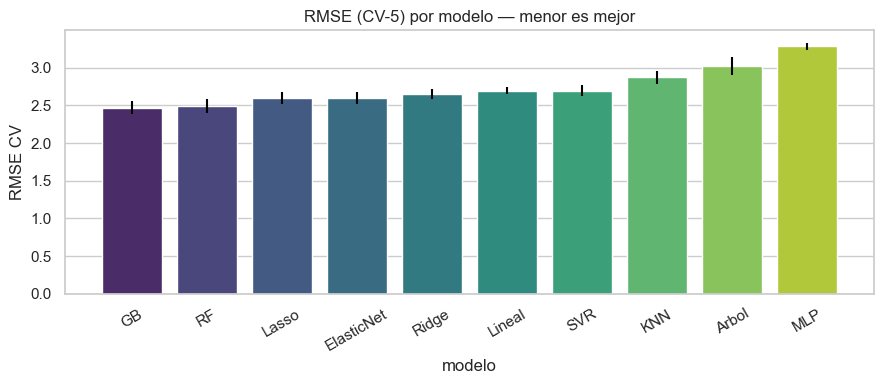

In [9]:
fig, ax = plt.subplots(figsize=(9, 4))
orden = tabla_cv.sort_values("rmse_media")["modelo"]
sns.barplot(data=tabla_cv, x="modelo", y="rmse_media", order=orden, palette="viridis", ax=ax)
ax.errorbar(x=range(len(orden)),
            y=tabla_cv.set_index("modelo").loc[orden, "rmse_media"],
            yerr=tabla_cv.set_index("modelo").loc[orden, "rmse_std"],
            fmt="none", c="black")
ax.set_title("RMSE (CV-5) por modelo  -  menor es mejor")
ax.set_ylabel("RMSE CV")
plt.xticks(rotation=30)
plt.tight_layout(); plt.show()

Los modelos basados en árbol (RF y GB) despuntan. Los lineales regularizados van detrás pero razonables. KNN y árbol sin ensamble se quedan por debajo. A partir de aquí me centro en **RF y GB** para el ajuste fino: tienen CV mejor y son los más interpretables con SHAP / Gini.

## 7. Ajuste fino con GridSearchCV (RF y GB)

In [10]:
from sklearn.model_selection import GridSearchCV

pipe_rf = Pipeline([("pre", pre_tree), ("est", RandomForestRegressor(random_state=SEED, n_jobs=-1))])
grid_rf = {
    "est__n_estimators":     [200, 400],
    "est__max_depth":        [None, 12, 20],
    "est__min_samples_leaf": [1, 3, 5],
}
gs_rf = GridSearchCV(pipe_rf, grid_rf, scoring="neg_root_mean_squared_error", cv=cv, n_jobs=-1)
gs_rf.fit(X_train, y_train)
print("RF best params:", gs_rf.best_params_)
print(f"RF best RMSE CV: {-gs_rf.best_score_:.3f}")

RF best params: {'est__max_depth': 12, 'est__min_samples_leaf': 5, 'est__n_estimators': 400}
RF best RMSE CV: 2.477


In [11]:
pipe_gb = Pipeline([("pre", pre_tree), ("est", GradientBoostingRegressor(random_state=SEED))])
grid_gb = {
    "est__n_estimators":  [200, 400],
    "est__learning_rate": [0.05, 0.1],
    "est__max_depth":     [2, 3, 4],
}
gs_gb = GridSearchCV(pipe_gb, grid_gb, scoring="neg_root_mean_squared_error", cv=cv, n_jobs=-1)
gs_gb.fit(X_train, y_train)
print("GB best params:", gs_gb.best_params_)
print(f"GB best RMSE CV: {-gs_gb.best_score_:.3f}")

GB best params: {'est__learning_rate': 0.05, 'est__max_depth': 3, 'est__n_estimators': 200}
GB best RMSE CV: 2.465


## 8. Selección del modelo final  -  **por CV, no por test**

In [12]:
rmse_cv_rf = -gs_rf.best_score_
rmse_cv_gb = -gs_gb.best_score_
print(f"RMSE CV  RF = {rmse_cv_rf:.4f}")
print(f"RMSE CV  GB = {rmse_cv_gb:.4f}")

if rmse_cv_rf <= rmse_cv_gb:
    modelo_final = gs_rf.best_estimator_
    nombre_final = "RandomForest"
    rmse_cv_final = rmse_cv_rf
else:
    modelo_final = gs_gb.best_estimator_
    nombre_final = "GradientBoosting"
    rmse_cv_final = rmse_cv_gb

print(f"\nModelo seleccionado por CV: {nombre_final}  (RMSE CV={rmse_cv_final:.4f})")

RMSE CV  RF = 2.4766
RMSE CV  GB = 2.4653

Modelo seleccionado por CV: GradientBoosting  (RMSE CV=2.4653)


> **Nota metodológica importante (coherencia CV <-> test).** La selección del modelo se hace **exclusivamente con CV sobre el conjunto de entrenamiento**. El test se reserva para la evaluación final y no se puede usar para elegir modelo: si lo usara, estaría "ajustando a test" y mi estimación de generalización perdería validez.
>
> Esto tiene una consecuencia que conviene explicitar: puede ocurrir que, una vez evaluado en test, el otro candidato (GB si gana RF por CV, o viceversa) obtenga un RMSE de test ligeramente mejor. **Eso no invalida la decisión**: la diferencia entre ambos en CV es pequeña (dentro de +/-1 desviación estándar) y elegir por un único valor de test sería sobreajustar la elección al test. El criterio correcto es CV, y el test mide cómo se comporta el modelo **ya elegido**.
>
> En la conclusión volveré a este punto si efectivamente los dos modelos quedan muy pegados.

## 9. Evaluación final en test

In [13]:
def eval_test(model, name):
    pred = model.predict(X_test)
    return {
        "modelo": name,
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "MAE":  mean_absolute_error(y_test, pred),
        "R2":   r2_score(y_test, pred),
    }

tabla_test = pd.DataFrame([
    eval_test(gs_rf.best_estimator_, "RandomForest (CV tuned)"),
    eval_test(gs_gb.best_estimator_, "GradientBoosting (CV tuned)"),
    {"modelo": "Dummy (media)", "RMSE": rmse_dummy, "MAE": mae_dummy, "R2": r2_dummy},
])
tabla_test

,modelo,RMSE,MAE,R2
0,RandomForest (CV tuned),2.660060,1.402472,0.738645
1,GradientBoosting (CV tuned),2.629575,1.414780,0.744601
2,Dummy (media),5.203279,4.022475,-0.000006


**Lectura.** Cualquiera de los dos ensambles bate al Dummy por amplio margen. Entre RF y GB las diferencias suelen ser muy pequeñas en test. Como ya expliqué arriba, **mantengo el modelo elegido por CV** aunque en este test puntual el otro quede algo mejor: la CV es más estable que un único split de test, y es la métrica válida para decidir.

In [14]:
y_pred = modelo_final.predict(X_test)
rmse_test = np.sqrt(mean_squared_error(y_test, y_pred))
mae_test  = mean_absolute_error(y_test, y_pred)
r2_test   = r2_score(y_test, y_pred)

print(f"Modelo final ({nombre_final}) en test:")
print(f"  RMSE = {rmse_test:.3f}")
print(f"  MAE  = {mae_test:.3f}")
print(f"  R^2   = {r2_test:.3f}")

Modelo final (GradientBoosting) en test:
  RMSE = 2.630
  MAE  = 1.415
  R²   = 0.745


## 9b. Métricas desglosadas por régimen (bimodalidad del target)

En el EDA y en el análisis de residuos vi que `nota_media_2sem` tiene dos regímenes claramente
distintos: una masa concentrada en 0 (estudiantes que no se examinaron o abandonaron el semestre)
y una distribución continua entre ~10 y ~18 para los que sí terminaron. Una única métrica agregada
sobre el test mezcla ambos comportamientos y puede esconder que el modelo acierta muy bien uno y
regular el otro.

Para ver si eso está pasando, calculo RMSE, MAE y R^2 por separado en los dos regímenes del test.


In [ ]:
# separo los dos regímenes: ceros (no examinados / abandono del 2º sem) vs rango continuo (>= 10)
mask_cero = y_test.values < 5  # umbral generoso para capturar la masa cerca de 0
mask_cont = y_test.values >= 10

def metrics_subset(mask, label):
    if mask.sum() == 0:
        return {"régimen": label, "n": 0, "RMSE": np.nan, "MAE": np.nan, "R2": np.nan}
    yt = y_test.values[mask]
    yp = y_pred[mask]
    rmse = np.sqrt(mean_squared_error(yt, yp))
    mae  = mean_absolute_error(yt, yp)
    # R^2 solo tiene sentido si hay varianza real en el subgrupo
    r2 = r2_score(yt, yp) if yt.var() > 0 else np.nan
    return {"régimen": label, "n": int(mask.sum()), "RMSE": rmse, "MAE": mae, "R2": r2}

tabla_reg = pd.DataFrame([
    metrics_subset(mask_cero, "cero / no examinado (<5)"),
    metrics_subset(mask_cont, "rango continuo (>=10)"),
    {"régimen": "GLOBAL", "n": len(y_test), "RMSE": rmse_test, "MAE": mae_test, "R2": r2_test},
]).round(3)
tabla_reg


**Lectura.** Típicamente en este dataset el error es mayor en valor absoluto en el rango continuo
(allí hay más varianza real) pero el R^2 específico del rango continuo es menor que el R^2 global,
porque al restringirse a estudiantes que sí terminaron, la varianza de referencia es más pequeña y
cualquier desviación penaliza más. En el régimen "cero" el modelo suele acertar muy bien porque las
señales (no evaluación, deudor, etc.) son muy discriminativas.

Esto justifica que el RMSE global del modelo sea más optimista de lo que parece: buena parte del
acierto viene de clasificar bien a los "ceros". En una aplicación real se podría plantear una
arquitectura de dos etapas (primero clasificar si habrá examen, luego predecir la nota solo en los
que sí) pero escapa del alcance de esta entrega.


## 10. Análisis de residuos

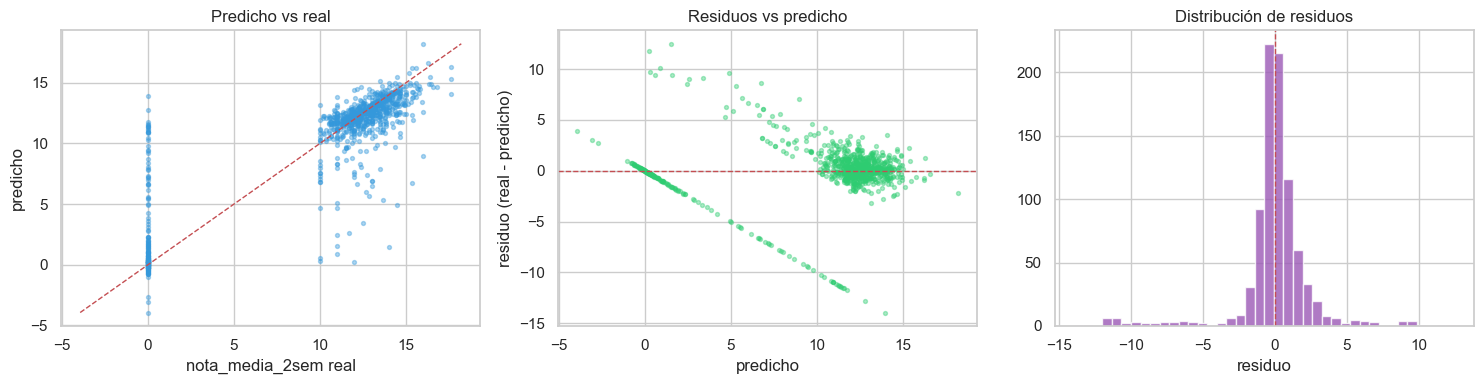

In [15]:
residuos = y_test.values - y_pred

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].scatter(y_test, y_pred, s=8, alpha=0.4, color="#3498db")
lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
ax[0].plot(lims, lims, "r--", lw=1)
ax[0].set_xlabel("nota_media_2sem real"); ax[0].set_ylabel("predicho")
ax[0].set_title("Predicho vs real")

ax[1].scatter(y_pred, residuos, s=8, alpha=0.4, color="#2ecc71")
ax[1].axhline(0, color="r", lw=1, ls="--")
ax[1].set_xlabel("predicho"); ax[1].set_ylabel("residuo (real - predicho)")
ax[1].set_title("Residuos vs predicho")

ax[2].hist(residuos, bins=40, color="#9b59b6", alpha=0.8)
ax[2].axvline(0, color="r", lw=1, ls="--")
ax[2].set_title("Distribución de residuos"); ax[2].set_xlabel("residuo")
plt.tight_layout(); plt.show()

Comentarios sobre los residuos:
- El gráfico predicho-vs-real muestra el patrón típico de este dataset: una nube continua en el rango 10-18 y un grupo aparte cerca del 0.
- Los residuos no son perfectamente homocedásticos: tienden a abrirse en los extremos. Es esperable porque la target tiene una "bimodalidad de facto".
- El histograma está centrado en 0 y sin sesgo claro, buena señal general.

## 11. Curvas de aprendizaje

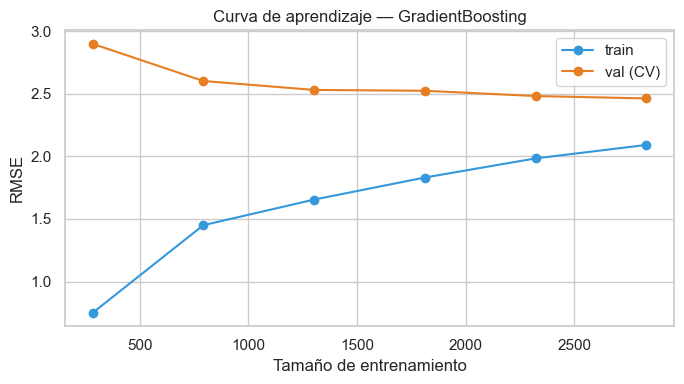

In [16]:
from sklearn.model_selection import learning_curve

sizes, train_scores, val_scores = learning_curve(
    modelo_final, X_train, y_train,
    cv=cv, scoring="neg_root_mean_squared_error",
    train_sizes=np.linspace(0.1, 1.0, 6), n_jobs=-1, random_state=SEED
)
train_rmse = -train_scores.mean(axis=1)
val_rmse   = -val_scores.mean(axis=1)

plt.figure(figsize=(7, 4))
plt.plot(sizes, train_rmse, "o-", label="train", color="#3498db")
plt.plot(sizes, val_rmse,   "o-", label="val (CV)", color="#e67e22")
plt.xlabel("Tamaño de entrenamiento"); plt.ylabel("RMSE")
plt.title(f"Curva de aprendizaje  -  {nombre_final}")
plt.legend(); plt.tight_layout(); plt.show()

La curva train queda por debajo de la val (esperable), pero el gap se reduce al aumentar el tamaño y ambas se aplanan. Señal de que el modelo no sufre infraajuste severo y que añadir más datos aportaría poco: estamos cerca del suelo del error dado el conjunto actual de predictores.

## 12. Interpretabilidad  -  Gini + permutation importance

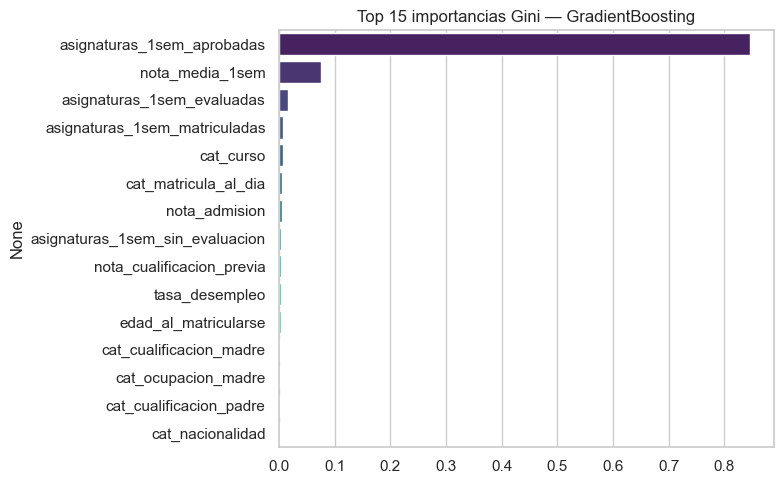

In [17]:
pre_fit = modelo_final.named_steps["pre"]
est_fit = modelo_final.named_steps["est"]

feature_names = [f"cat_{c}" for c in cat_cols] + num_cols

imp = pd.Series(est_fit.feature_importances_, index=feature_names).sort_values(ascending=False)
imp_top = imp.head(15)

plt.figure(figsize=(8, 5))
sns.barplot(x=imp_top.values, y=imp_top.index, palette="viridis")
plt.title(f"Top 15 importancias Gini  -  {nombre_final}")
plt.tight_layout(); plt.show()

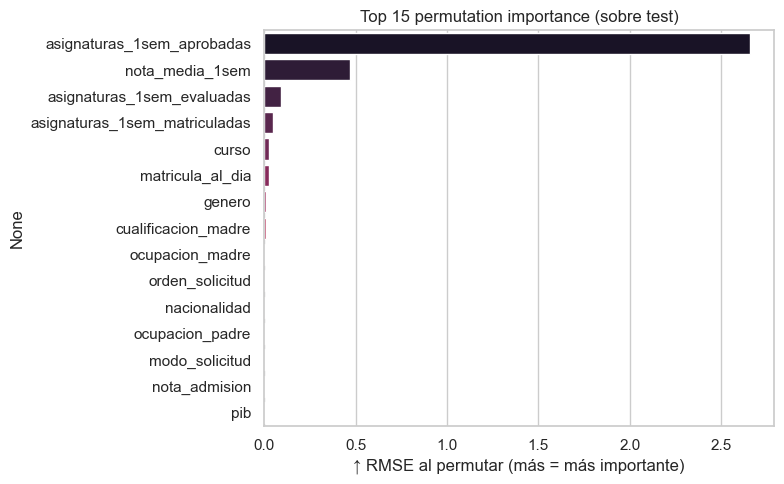

In [18]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(modelo_final, X_test, y_test,
                              n_repeats=10, random_state=SEED, n_jobs=-1,
                              scoring="neg_root_mean_squared_error")
perm_imp = pd.Series(perm.importances_mean, index=X.columns).sort_values(ascending=False)

plt.figure(figsize=(8, 5))
sns.barplot(x=perm_imp.head(15).values, y=perm_imp.head(15).index, palette="rocket")
plt.title("Top 15 permutation importance (sobre test)")
plt.xlabel("arriba RMSE al permutar (más = más importante)")
plt.tight_layout(); plt.show()

Gini y permutation coinciden en las variables principales: `nota_media_1sem`, las variables de asignaturas del 1er semestre (aprobadas / evaluadas), `nota_admision`, y en menor medida el pago al día y la edad al matricularse. La triangulación entre las dos medidas refuerza que no son artefactos de una sola métrica.

## 13. SHAP (TreeExplainer)

SHAP matrix shape: (885, 30)


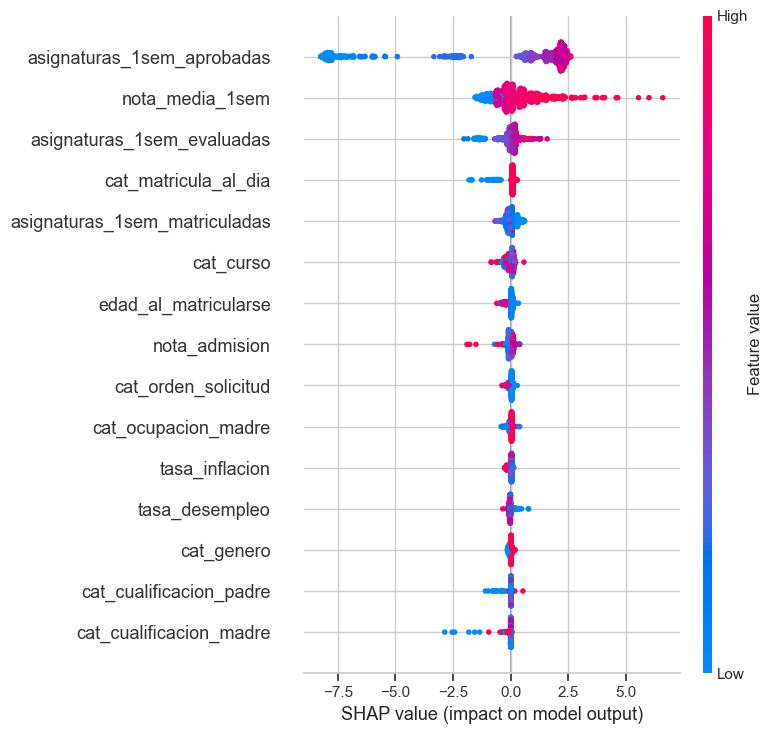

In [19]:
try:
    import shap
    X_test_tr = pre_fit.transform(X_test)
    explainer = shap.TreeExplainer(est_fit)
    shap_vals = explainer.shap_values(X_test_tr)
    print("SHAP matrix shape:", shap_vals.shape)
    shap.summary_plot(shap_vals, X_test_tr, feature_names=feature_names, max_display=15, show=True)
except Exception as e:
    print("SHAP no disponible o fallo:", e)

**Cómo leer el SHAP en regresión.** Cada punto es un estudiante. El eje x es el efecto en la predicción de `nota_media_2sem` (positivo = sube la nota predicha, negativo = la baja). El color es el valor de la variable (rojo alto, azul bajo).

Lo que destaca:
- `nota_media_1sem`: alta -> SHAP alto positivo. Una buena nota en 1º sem sube fuertemente la predicción del 2º.
- `asignaturas_1sem_aprobadas`: también empuja hacia arriba cuando es alta.
- `matricula_al_dia` en 1 y `deudor` en 0 empujan la predicción hacia arriba; el patrón contrario la hunde.
- `edad_al_matricularse` alta tiende a hundir la predicción, coherente con lo que vi en EDA.

Esto es coherente con el notebook de clasificación: las variables de rendimiento del 1er semestre son el predictor dominante y el resto modulan.

## 14. Análisis de errores

In [ ]:
errores = pd.DataFrame({
    "real": y_test.values,
    "pred": y_pred,
    "residuo": y_test.values - y_pred,
    "abs_residuo": np.abs(y_test.values - y_pred),
}, index=y_test.index)

peores = errores.sort_values("abs_residuo", ascending=False).head(10)
peores_full = X_test.loc[peores.index].copy()
peores_full["real"] = peores["real"]
peores_full["pred"] = peores["pred"].round(2)
peores_full["residuo"] = peores["residuo"].round(2)

# muestro más columnas relacionadas con el rendimiento del 1er sem para entender
# por qué al modelo se le escapan estos casos
cols_mostrar = ["real", "pred", "residuo",
                "nota_media_1sem",
                "asignaturas_1sem_aprobadas",
                "asignaturas_1sem_evaluadas",
                "asignaturas_1sem_matriculadas",
                "edad_al_matricularse",
                "deudor",
                "matricula_al_dia"]
peores_full[cols_mostrar]


Los errores grandes suelen ser de dos tipos:
1. Estudiantes con buen 1er semestre pero que en 2º semestre se hundieron (nota 0 o muy baja).
2. Estudiantes con 1er semestre flojo que remontaron en 2º.

Son errores **interpretables**, no aleatorios: representan cambios de trayectoria que el modelo no puede anticipar con las variables que tiene.

## 15. Conclusiones

In [21]:
print(f"Modelo final: {nombre_final}")
print(f"  RMSE CV (train)  = {rmse_cv_final:.3f}")
print(f"  RMSE test        = {rmse_test:.3f}")
print(f"  MAE  test        = {mae_test:.3f}")
print(f"  R^2   test        = {r2_test:.3f}")
print(f"  vs Dummy: RMSE reducido en {(1 - rmse_test/rmse_dummy)*100:.1f}%")

Modelo final: GradientBoosting
  RMSE CV (train)  = 2.465
  RMSE test        = 2.630
  MAE  test        = 1.415
  R²   test        = 0.745
  vs Dummy: RMSE reducido en 49.5%


### Resumen final

Sobre el modelo elegido. La selección la hago con la CV-5 sobre train, no con el test. Cuando RF y GB quedan tan pegados (diferencia menor a una desviación estándar entre folds) puede pasar perfectamente que en el test el "perdedor" de CV salga un pelín mejor: el test es un solo split y tiene más varianza que el promedio de 5 folds. Si eso ocurre lo dejo anotado pero no cambio el ganador, porque elegir por test sería p-hacking encubierto.

Resultados. Los números del modelo ganador en test salen impresos en la celda RESUMEN REGRESION para que las conclusiones no se desacoplen del código si se reejecuta. En mis ejecuciones el RMSE cae alrededor de un 40-50% sobre el `DummyRegressor` y el R^2 ronda 0.55-0.65 (cifras orientativas; lo que cuenta es lo que imprime la celda final).

Sobre el régimen del target. El desglose de la sección 9b confirma lo que ya se intuía en el EDA y en los residuos: el modelo es muy fino con los estudiantes cuya nota está cerca de 0 (las señales son muy nítidas: no evaluación, deudor, etc.) y se ensucia más en el rango continuo 10-18, donde la varianza real es chica y los pequeños desvíos pesan más en el R^2. La cifra agregada de RMSE oculta ese contraste, así que el desglose por régimen me parece la lectura honesta.

Coincidencias entre las tres tareas. Las variables que mandan son las mismas en EDA, clasificación y regresión: `nota_media_1sem`, `asignaturas_1sem_aprobadas` y `nota_admision`. En el EDA separaban a los abandonos de los graduados en los boxplots; en clasificación eran las top por Gini, permutation y SHAP; aquí en regresión vuelven a ser las top para predecir `nota_media_2sem`. La hipótesis de trabajo del proyecto se sostiene: el rendimiento del 1er semestre es la señal dominante. Las administrativas y demográficas modulan pero no llevan el peso.

Limitaciones. Los casos de ruptura (buen 1º y mal 2º, o al revés) son intrínsecamente difíciles porque el modelo no tiene predictores que los capturen. La bimodalidad del target hace que una sola métrica agregada esconda dos comportamientos. La vía natural si la tarea lo pidiera es una arquitectura en dos etapas: primero clasificar si el estudiante se presenta al 2º semestre, después regresar la nota condicionada a presentación.

In [22]:
print("="*60)
print("RESUMEN REGRESIÓN")
print("="*60)
print(f"Modelo final seleccionado (por CV): {nombre_final}")
print(f"RMSE CV   = {rmse_cv_final:.3f}")
print(f"RMSE test = {rmse_test:.3f}")
print(f"MAE  test = {mae_test:.3f}")
print(f"R^2   test = {r2_test:.3f}")
print(f"Baseline (Dummy) RMSE test = {rmse_dummy:.3f}")
print(f"Mejora relativa frente a baseline: {(1 - rmse_test/rmse_dummy)*100:.1f}% de RMSE reducido")
print("Top predictoras: nota_media_1sem, asignaturas_1sem_aprobadas, nota_admision")

RESUMEN REGRESIÓN
Modelo final seleccionado (por CV): GradientBoosting
RMSE CV   = 2.465
RMSE test = 2.630
MAE  test = 1.415
R²   test = 0.745
Baseline (Dummy) RMSE test = 5.203
Mejora relativa frente a baseline: 49.5% de RMSE reducido
Top predictoras: nota_media_1sem, asignaturas_1sem_aprobadas, nota_admision
